# Interpretable Road Damage Detection for Intelligent Transportation Systems using YOLOv8 Nano and EigenCAM

## Explainability Analysis using EigenCAM

Object detection models typically provide only bounding-box predictions without revealing which image regions contributed most strongly to those predictions. To improve model interpretability, EigenCAM is applied to the trained YOLOv8 Nano detector.

Unlike gradient-based visualization methods, EigenCAM produces class-independent activation maps directly from feature representations, making it computationally efficient while providing intuitive visual explanations. The resulting heatmaps highlight the regions that contribute most strongly to the detector's learned representations.

## Objectives

- Load the trained YOLOv8 Nano model
- Load representative road damage images
- Generate EigenCAM visualizations
- Compare multiple feature layers
- Identify the most informative feature layer
- Interpret the model's visual attention

In [56]:
# ==========================================================
# Install Required Libraries
# ==========================================================

!pip install -q ultralytics
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 50.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [57]:
# ==========================================================
# Import Required Libraries
# ==========================================================

import os
import cv2
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("Libraries imported successfully!")

Libraries imported successfully!


In [58]:
# ==========================================================
# Download Sample Image from GitHub
# ==========================================================

IMAGE_URL = "https://raw.githubusercontent.com/codes4vinay/Explainable-Road-Damage-Detection/main/figures/original_test_image.png"
IMAGE_PATH = "/content/original_test_image.png"

if not os.path.exists(IMAGE_PATH):
    urllib.request.urlretrieve(IMAGE_URL, IMAGE_PATH)

print("✅ Sample image ready:", IMAGE_PATH)

✅ Sample image ready: /content/original_test_image.png


## Load the Trained YOLOv8 Model

The best-performing YOLOv8 Nano model obtained during training is loaded for explainability analysis. The model weights correspond to the detector trained on the custom road damage dataset containing cracks, manholes, and potholes.

In [59]:
# ==========================================================
# Load the trained YOLOv8 model
# ==========================================================

model = YOLO("/content/best.pt")

print("✅ Trained YOLOv8 model loaded successfully!")

✅ Trained YOLOv8 model loaded successfully!


## Clone the EigenCAM Repository

The EigenCAM implementation is provided through the **YOLO-V8-CAM** repository. This implementation supports visualization of intermediate feature representations for YOLOv8 object detection models.

In [60]:
# ==========================================================
# Clone the YOLO-V8-CAM repository
# ==========================================================

!git clone https://github.com/rigvedrs/YOLO-V8-CAM.git

fatal: destination path 'YOLO-V8-CAM' already exists and is not an empty directory.


## Import EigenCAM Utilities

The required visualization utilities are imported from the cloned repository to generate activation maps and overlay them on the original road image.

In [61]:
# ==========================================================
# Install EigenCAM dependencies
# ==========================================================

!pip install -q ttach

In [62]:
# ==========================================================
# Import EigenCAM
# ==========================================================

import sys

sys.path.append("/content/YOLO-V8-CAM")

from yolo_cam.eigen_cam import EigenCAM
from yolo_cam.utils.image import show_cam_on_image

print("✅ EigenCAM imported successfully!")

✅ EigenCAM imported successfully!


## Select the Target Feature Layer

EigenCAM can visualize different intermediate feature representations of the YOLOv8 backbone and neck. Multiple feature layers were evaluated experimentally, and the second-to-last feature layer (`-2`) produced the clearest and most informative activation maps for road damage detection.

In [63]:
# ==========================================================
# Select the target feature layer
# ==========================================================

target_layers = [model.model.model[-2]]

print("Selected target layer:")
print(target_layers[0])

Selected target layer:
C2f(
  (cv1): Conv(
    (conv): Conv2d(384, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(384, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): ModuleList(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)


In [64]:
# ==========================================================
# Initialize EigenCAM
# ==========================================================

cam = EigenCAM(
    model,
    target_layers,
    task="od"
)

print("✅ EigenCAM initialized successfully!")

✅ EigenCAM initialized successfully!


In [65]:
# ==========================================================
# Load sample image for EigenCAM
# ==========================================================

image_path = "/content/original_test_image.png"

img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

img = cv2.resize(img, (640, 640))

rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_float = np.float32(rgb_img) / 255.0

print("✅ Image loaded successfully!")
print(rgb_img.shape)

✅ Image loaded successfully!
(640, 640, 3)



0: 640x640 1 crack, 1022.1ms
Speed: 11.8ms preprocess, 1022.1ms inference, 5.4ms postprocess per image at shape (1, 3, 640, 640)


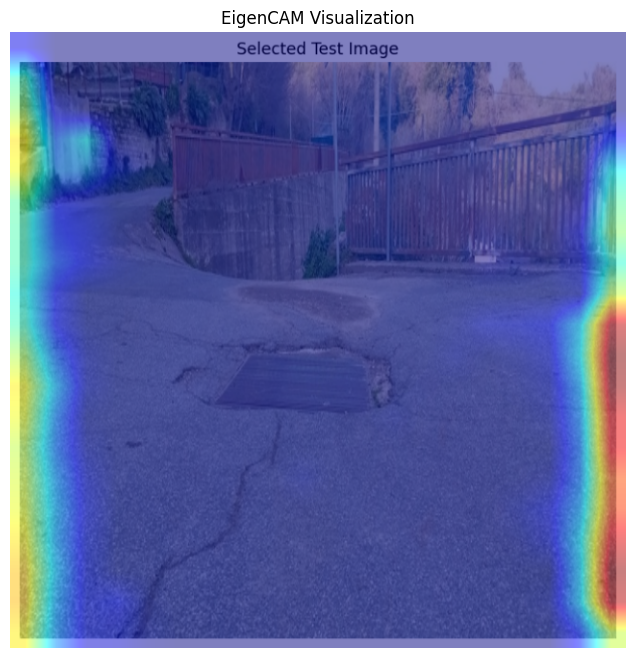

In [66]:
# ==========================================================
# Generate EigenCAM Visualization
# ==========================================================

grayscale_cam = cam(rgb_img)[0, :, :]

cam_image = show_cam_on_image(
    img_float,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(8,8))
plt.imshow(cam_image)
plt.title("EigenCAM Visualization")
plt.axis("off")
plt.show()

# Compare multiple feature layers using EigenCAM

## Feature Layer Comparison

To identify the most informative feature representation for explainability, EigenCAM is applied to multiple intermediate feature layers of the trained YOLOv8 Nano model. Specifically, Layers **−2**, **−3**, **−4**, and **−5** are evaluated and compared qualitatively.

The objective is to determine which layer produces the clearest and most interpretable activation map while maintaining strong localization around the detected road damage. Based on the comparison, the most suitable layer is selected for the final visualization.


0: 640x640 1 crack, 642.8ms
Speed: 8.8ms preprocess, 642.8ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 crack, 546.3ms
Speed: 6.3ms preprocess, 546.3ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 crack, 899.3ms
Speed: 12.2ms preprocess, 899.3ms inference, 6.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 crack, 743.5ms
Speed: 12.2ms preprocess, 743.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


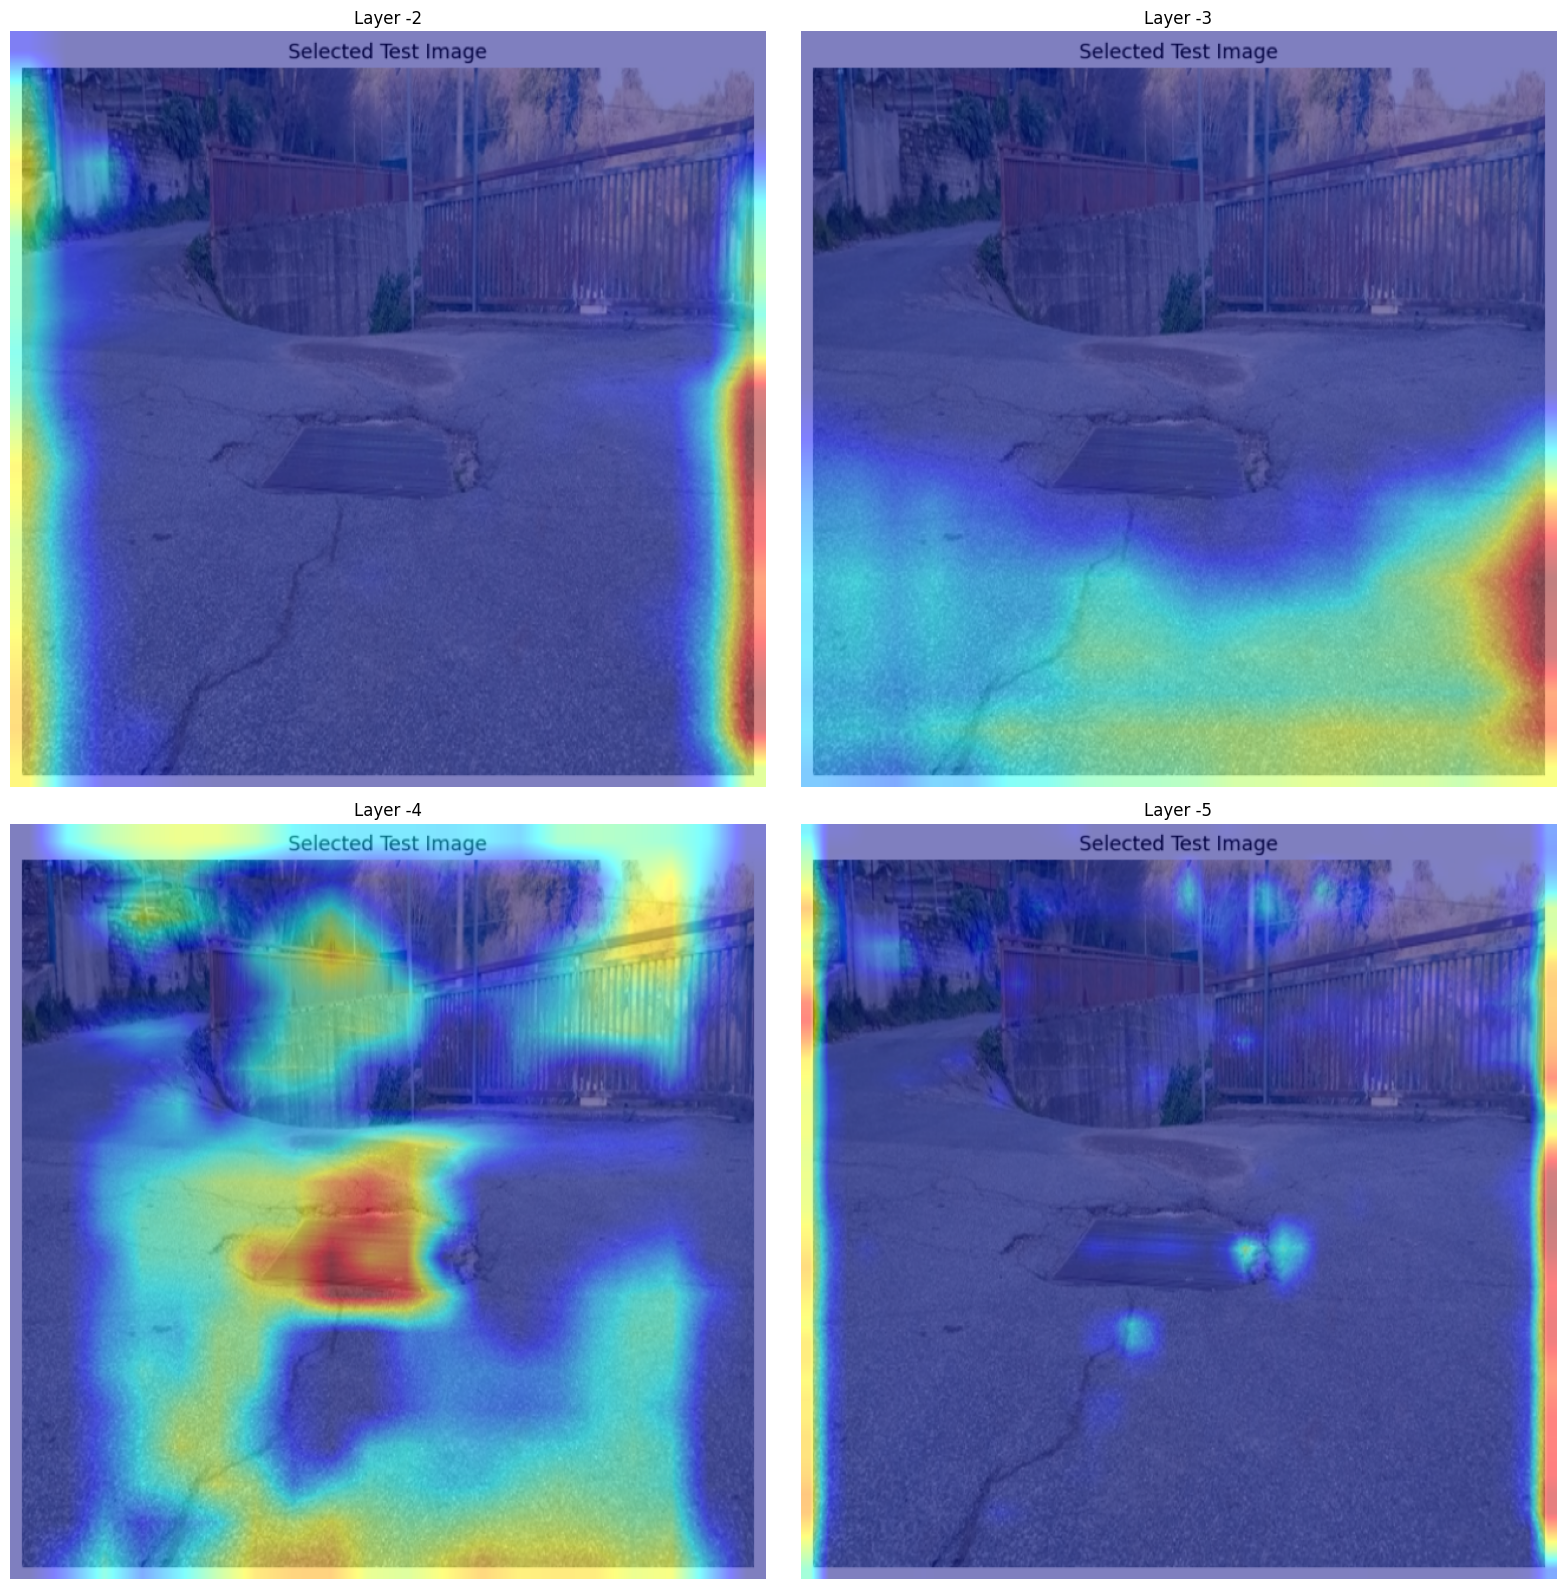

In [67]:
# ==========================================================
# Compare multiple feature layers using EigenCAM
# ==========================================================


layers = [-2, -3, -4, -5]

plt.figure(figsize=(16,16))

for i, layer in enumerate(layers):

    cam = EigenCAM(
        model,
        [model.model.model[layer]],
        task="od"
    )

    grayscale_cam = cam(rgb_img)[0]

    cam_image = show_cam_on_image(
        img_float,
        grayscale_cam,
        use_rgb=True
    )

    plt.subplot(2,2,i+1)
    plt.imshow(cam_image)
    plt.title(f"Layer {layer}")
    plt.axis("off")

plt.tight_layout()
plt.show()


0: 640x640 1 crack, 699.1ms
Speed: 12.1ms preprocess, 699.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


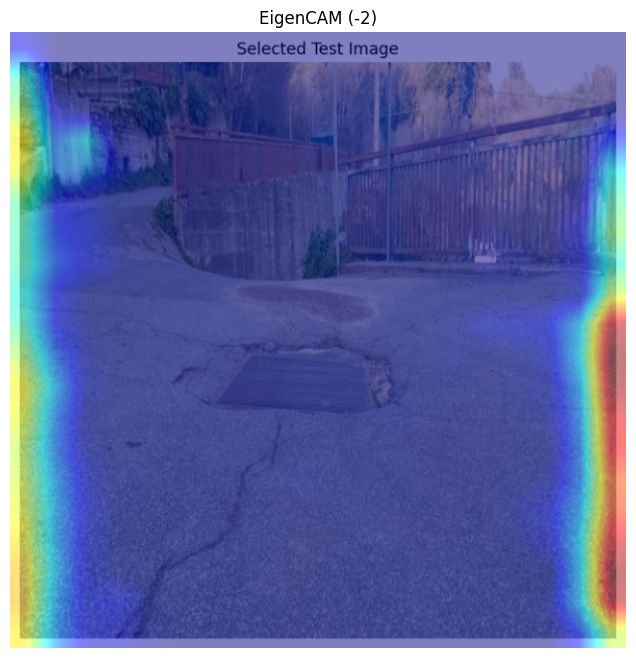

In [68]:
cam = EigenCAM(
    model,
    [model.model.model[-2]],
    task="od"
)

grayscale_cam = cam(rgb_img)[0]

cam_image = show_cam_on_image(
    img_float,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(8,8))
plt.imshow(cam_image)
plt.title("EigenCAM (-2)")
plt.axis("off")
plt.show()

## Discussion

The EigenCAM visualizations provide qualitative insight into the internal feature representations learned by the trained YOLOv8 Nano model. The strongest activations are concentrated around the damaged pavement, particularly near the detected manhole and surrounding crack regions, indicating that the model primarily relies on meaningful road-surface features when making predictions.

Feature maps from four intermediate layers (-2, -3, -4, and -5) were compared to investigate how different network depths influence the visualization. Among these, **Layer -2** produced the clearest and most interpretable activation map, maintaining strong emphasis on the damaged pavement while preserving useful spatial information. Earlier layers generated broader activations, whereas deeper layers became increasingly sparse and highlighted less relevant contextual regions.

Although moderate activation is observed over background structures such as vegetation and roadside barriers, the dominant responses remain localized around the damaged road surface. This suggests that the detector has learned meaningful representations of road defects rather than relying solely on surrounding scene context.

These qualitative observations complement the quantitative detection performance of the trained YOLOv8 Nano model and demonstrate how explainability techniques can improve transparency, interpretability, and user confidence in AI-based infrastructure inspection systems.

## Conclusion

This notebook demonstrated how EigenCAM can be integrated with a custom-trained YOLOv8 Nano model to improve the interpretability of road damage detection.

Using a representative sample image, EigenCAM successfully highlighted the regions that contributed most strongly to the model's learned feature representations. Qualitative comparison of multiple intermediate feature layers (-2, -3, -4, and -5) showed that **Layer −2** produced the clearest and most informative activation maps while preserving accurate localization around the damaged pavement.

The combination of lightweight object detection and feature-level explainability provides a transparent computer vision workflow for intelligent transportation systems and automated infrastructure monitoring. Such explainability techniques improve trust, facilitate model debugging, and support the development of more reliable and responsible AI systems.

## References

1. Ultralytics YOLOv8  
   https://github.com/ultralytics/ultralytics

2. YOLO-V8-CAM Repository  
   https://github.com/rigvedrs/YOLO-V8-CAM

3. EigenCAM: Eigen-CAM: Class Activation Map using Principal Components  
   https://arxiv.org/abs/2008.00299